# How volatility timing changes momentum

This notebook isolates conventional momentum and its lagged-realized-variance-managed counterpart. It asks when the strategy changes exposure, how the return distribution changes, and which volatility and business-cycle states account for the timing payoff. It is a diagnostic analysis rather than a new strategy horse race.

In [1]:
# 0. Libraries and project modules
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))

from config import HAC_LAGS, MANAGED_FACTORS
from momentum_timing_analysis import (
    build_momentum_timing_sample, equal_volatility_timing_payoff,
    exposure_summary_table, momentum_distribution_table,
    recession_loading_table, recession_performance_table,
    rolling_strategy_relationships, strategy_comovement_table,
    timing_payoff_contribution_table, timing_payoff_summary,
    volatility_state_table,
)
from plots import (
    plot_momentum_return_cdf, plot_momentum_return_distributions,
    plot_momentum_rolling_relationships, plot_momentum_timing_payoff,
    plot_momentum_timing_series, plot_momentum_volatility_states,
)

## 1. Sample and timing rule

The sample is fixed to August 1927–July 2026 so the results reconcile exactly with Notebook 05. In month $t$, the stored strategy applies $w_t=c/\widehat{\sigma}_{t-1}^2$ to the contemporaneous momentum return. The variance is calculated from daily momentum returns in month $t-1$, so the weight uses no month-$t$ return. The constant $c$ was selected to match original momentum volatility through the April 2015 replication endpoint; it is an ex-post normalization and does not affect Sharpe ratios or alpha t-statistics. Weights are uncapped and not winsorized.

In [2]:
# 1. Load and validate the momentum-timing sample
managed_factors = pd.read_parquet(MANAGED_FACTORS)
analysis = build_momentum_timing_sample(
    managed_factors,
    start_date=pd.Timestamp('1927-08-31'),
    end_date=managed_factors['date'].max(),
)
print(
    f"Momentum-timing sample: {analysis.date.min():%Y-%m} to "
    f"{analysis.date.max():%Y-%m} ({len(analysis):,} months)."
)
print(
    'Identity verified: managed momentum = known beginning-of-month weight '
    '× contemporaneous momentum return.'
)

Momentum-timing sample: 1927-08 to 2026-07 (1,188 months).
Identity verified: managed momentum = known beginning-of-month weight × contemporaneous momentum return.


In [3]:
# 1.1 Summarize native exposure
exposure = exposure_summary_table(analysis)
exposure_display = exposure.set_index('Metric').T
display(exposure_display.style.format('{:.3f}'))

Metric,Lagged-RV normalization constant,Mean weight,Median weight,Weight standard deviation,Weight 5th percentile,Weight 95th percentile,Weight 99th percentile,Minimum weight,Maximum weight,Annualized weight turnover
Value,0.000,1.439,0.816,1.767,0.075,4.849,7.785,0.010,20.498,10.477


## 2. Volatility, exposure, and momentum through time

The panels make the mechanism visible: high lagged variance mechanically produces a low next-month exposure, while low lagged variance produces a high exposure. The Great Depression and the Global Financial Crisis are prominent examples in which volatility remains elevated and the strategy substantially reduces exposure. This is a reaction to the preceding month's volatility—not advance prediction of a recession's onset. The weight uses a log scale because the uncapped inverse-variance rule is strongly right-skewed. Gray regions are NBER recessions; those labels are retrospective context and are not used to form the strategy. Annualized weight turnover is the sum of absolute monthly changes in this scalar exposure and is not transaction-cost-adjusted portfolio turnover.

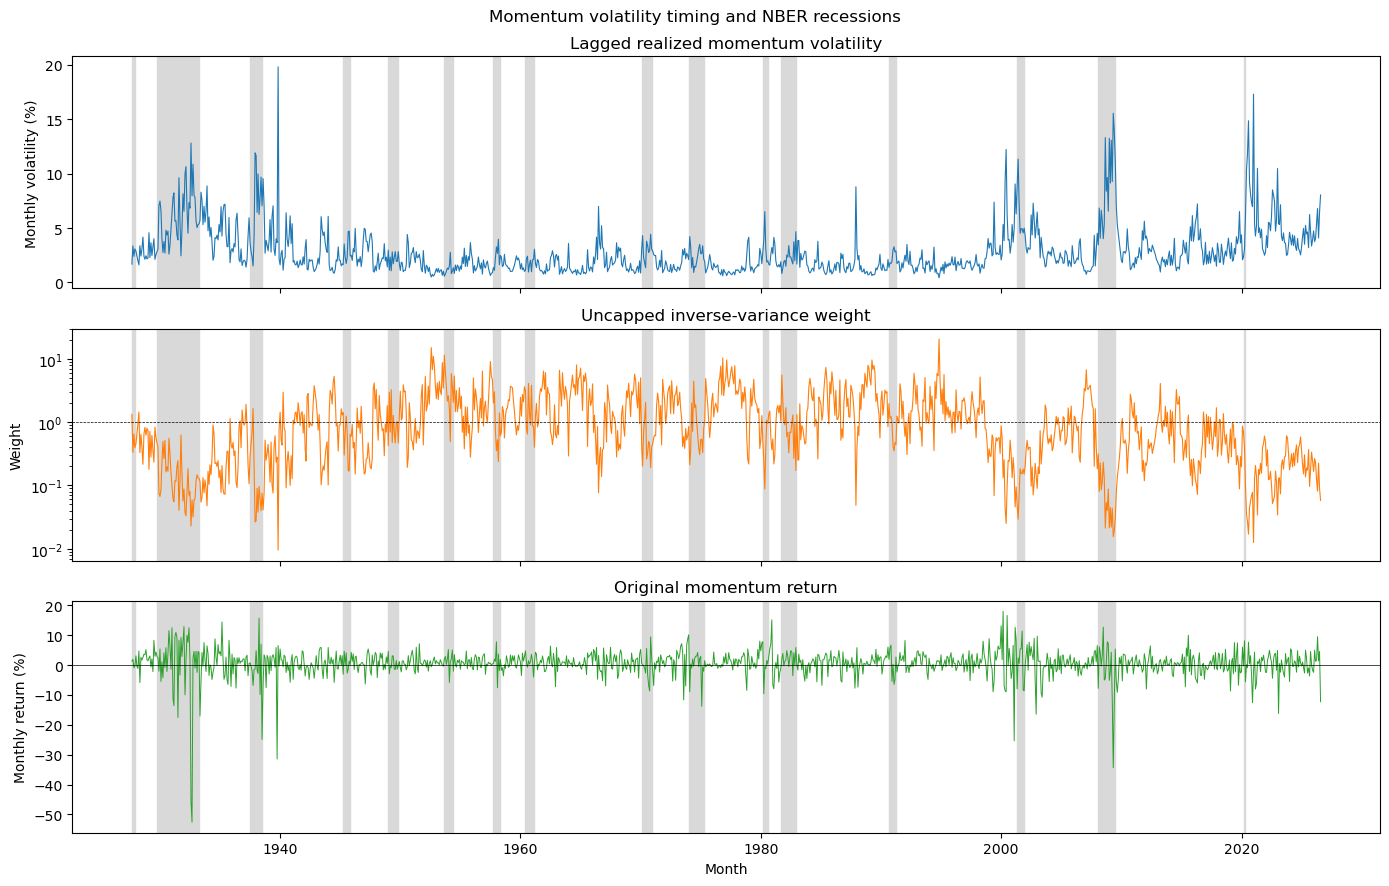

In [4]:
# 2. Plot the state variable, resulting exposure, and original return
plot_momentum_timing_series(analysis);

## 3. How the return distribution changes

All returns, quantiles, empirical 5% VaR/ES losses, and drawdowns are in percent. VaR is the loss at the fifth return percentile; ES is the average loss among observations at or below that threshold. These are unconditional historical estimates, not forecasts. Excess kurtosis is reported relative to the normal distribution. Native return scales are retained here, so changes reflect both timing and the stored normalization. Histograms and kernel-density estimates show the overall shape before the empirical cumulative distribution function (CDF).

In [5]:
# 3.1 Compare native monthly return distributions
distribution = momentum_distribution_table(analysis)
distribution_metrics = {
    'mean_monthly_pct': 'Mean monthly return (%)',
    'median_monthly_pct': 'Median monthly return (%)',
    'std_monthly_pct': 'Monthly standard deviation (%)',
    'annualized_sharpe': 'Annualized Sharpe ratio',
    'quantile_01_pct': '1st percentile (%)',
    'quantile_05_pct': '5th percentile (%)',
    'quantile_95_pct': '95th percentile (%)',
    'quantile_99_pct': '99th percentile (%)',
    'empirical_var_05_loss_pct': 'Empirical 5% VaR loss (%)',
    'empirical_es_05_loss_pct': 'Empirical 5% ES loss (%)',
    'skewness': 'Skewness',
    'excess_kurtosis': 'Excess kurtosis',
    'positive_months_pct': 'Positive months (%)',
    'worst_return_pct': 'Worst monthly return (%)',
    'best_return_pct': 'Best monthly return (%)',
    'maximum_drawdown_pct': 'Maximum drawdown (%)',
}
distribution_display = (
    distribution.set_index('strategy')[list(distribution_metrics)]
    .rename(columns=distribution_metrics).T
)
display(distribution_display.round(3))

strategy,Momentum,Lagged-RV volatility-timed momentum
Mean monthly return (%),0.609,1.231
Median monthly return (%),0.800,0.498
Monthly standard deviation (%),4.704,4.552
Annualized Sharpe ratio,0.449,0.937
1st percentile (%),-12.727,-9.567
5th percentile (%),-6.062,-4.332
95th percentile (%),6.432,8.975
99th percentile (%),11.425,17.411
Empirical 5% VaR loss (%),6.062,4.332
Empirical 5% ES loss (%),11.835,7.826


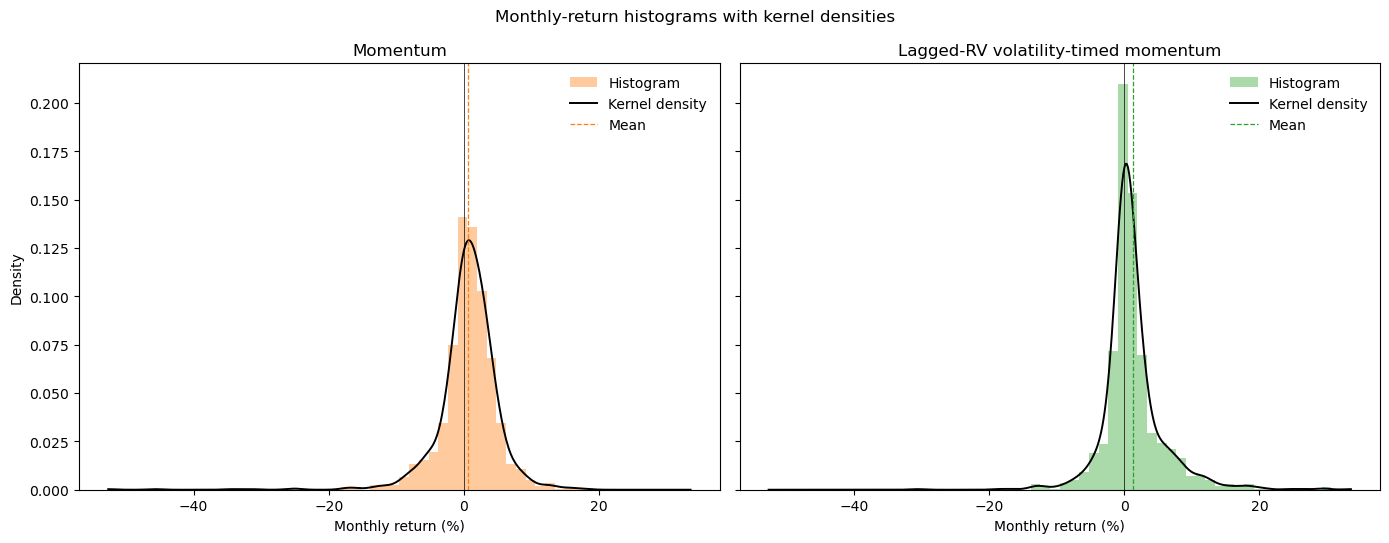

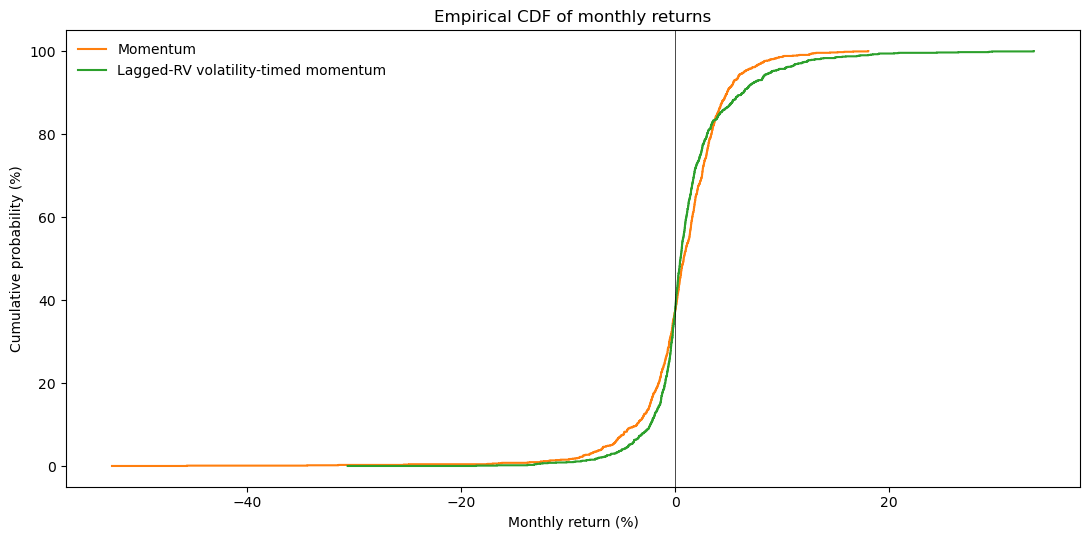

In [6]:
# 3.2 Compare distribution shapes and empirical CDFs
plot_momentum_return_distributions(analysis);
plot_momentum_return_cdf(analysis);

## 4. Outcomes across lagged-volatility states

Quintile 1 contains the 20% of months with the lowest preceding-month momentum variance; quintile 5 contains the highest 20%. Return columns describe month $t$ after sorting on variance observed in month $t-1$. The groups are full-sample descriptive bins—not estimated real-time trading thresholds.

The executed results distinguish absolute from relative Sharpe-ratio improvement. The highest Sharpe ratio remains in quintile 1: 1.648 for Mom and 1.609 for VT-Mom. Quintile 5 shows the largest improvement relative to Mom—from approximately 0.001 to 0.305—but not the highest Sharpe ratio. The full-sample gain arises because the strategy assigns high exposure to the attractive low-volatility states and very little exposure to the unattractive high-volatility states.

For raw Mom, the realized monthly mean falls from 0.895% in quintile 1 to 0.002% in quintile 5 while standard deviation rises from 1.882% to 8.180%. Sample means are noisy estimates of expected returns, but they clearly do not rise proportionally with risk here. Momentum may be especially exposed because it is long recent winners and short recent losers: after stressed markets, abrupt rebounds can make the short loser leg surge while previous winners lag. Such momentum crashes cluster in volatile reversal states. Crowded-position deleveraging may reinforce the pattern, but this project has not yet tested those holdings-level mechanisms, so they remain hypotheses rather than conclusions.

In [7]:
# 4.1 Summarize next-month outcomes by lagged-variance quintile
volatility_states = volatility_state_table(analysis)
state_labels = {
    'volatility_quintile': 'Volatility quintile',
    'observations': 'N',
    'average_lagged_volatility_pct': 'Lagged monthly volatility (%)',
    'average_weight': 'Average weight',
    'recession_months_pct': 'Recession months (%)',
    'negative_momentum_months_pct': 'Negative momentum months (%)',
    'mom_mean_monthly_pct': 'Mom mean (%)',
    'mom_std_monthly_pct': 'Mom std (%)',
    'mom_annualized_sharpe': 'Mom annualized SR',
    'managed_mean_monthly_pct': 'VT-Mom mean (%)',
    'managed_std_monthly_pct': 'VT-Mom std (%)',
    'managed_annualized_sharpe': 'VT-Mom annualized SR',
}
display(volatility_states.rename(columns=state_labels).round(3).style.hide(axis='index'))

Volatility quintile,N,Lagged monthly volatility (%),Average weight,Recession months (%),Negative momentum months (%),Mom mean (%),Mom std (%),Mom annualized SR,VT-Mom mean (%),VT-Mom std (%),VT-Mom annualized SR
1,238,0.997000,4.233000,5.882000,29.412000,0.895000,1.882000,1.648000,3.777000,8.131000,1.609000
2,237,1.544000,1.620000,8.861000,34.177000,1.023000,2.615000,1.355000,1.667000,4.137000,1.396000
3,238,2.180000,0.813000,15.126000,41.597000,0.559000,3.218000,0.601000,0.385000,2.588000,0.515000
4,237,3.159000,0.393000,18.565000,38.819000,0.570000,4.762000,0.415000,0.248000,1.868000,0.461000
5,238,6.285000,0.129000,32.353000,42.437000,0.002000,8.180000,0.001000,0.076000,0.857000,0.305000


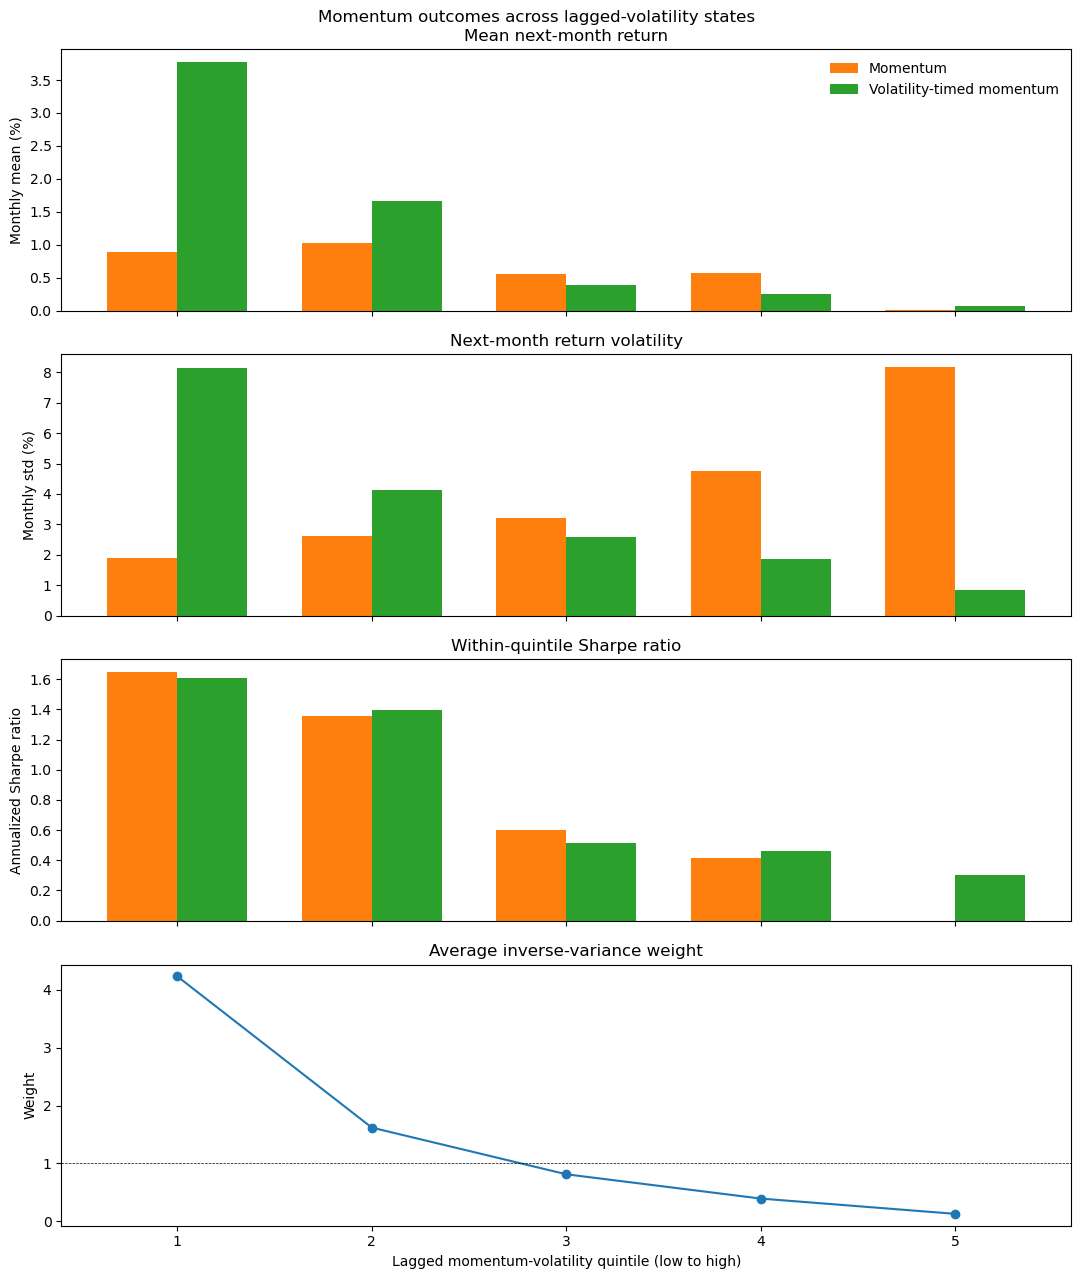

In [8]:
# 4.2 Visualize return means, risk, Sharpe ratios, and exposure by state
plot_momentum_volatility_states(volatility_states);

## 5. Where the volatility-timing payoff accumulates

To isolate timing from unconditional leverage, managed momentum is multiplied by one positive full-sample constant so its standard deviation equals original momentum's. The timing payoff is then equal-volatility managed momentum minus original momentum. This scale is ex post and diagnostic—not an implementable target-volatility rule. Its cumulative plot is the arithmetic sum of monthly return differences, not compounded wealth. The first table reports the mean payoff and its Newey–West(12) t-statistic conditional on that chosen scale; it does not account for the ex-post estimation of the scale. The contribution table shows how much each lagged-volatility quintile adds to the full-sample average payoff.

In [9]:
# 5.1 Build the equal-volatility timing payoff and decompose its mean
timing_payoff, equal_vol_scale = equal_volatility_timing_payoff(analysis)
payoff_summary = timing_payoff_summary(timing_payoff, HAC_LAGS)
payoff_contributions = timing_payoff_contribution_table(timing_payoff)
print(f'Full-sample equal-volatility multiplier on managed momentum: {equal_vol_scale:.3f}.')
summary_labels = {
    'mean_monthly_pct': 'Mean monthly timing payoff (%)',
    'nw12_t': 'Newey-West(12) t-statistic', 'observations': 'N',
}
display(payoff_summary.rename(columns=summary_labels).round(3).style.hide(axis='index'))
payoff_labels = {
    'volatility_quintile': 'Volatility quintile',
    'observations': 'N',
    'mean_timing_payoff_pct': 'Mean timing payoff (%)',
    'contribution_to_full_mean_pct': 'Contribution to full mean (%)',
}
display(payoff_contributions.rename(columns=payoff_labels).round(3).style.hide(axis='index'))

Full-sample equal-volatility multiplier on managed momentum: 1.033.


Mean monthly timing payoff (%),Newey-West(12) t-statistic,N
0.663000,4.026000,1188


Volatility quintile,N,Mean timing payoff (%),Contribution to full mean (%)
1,238,3.008000,0.603000
2,237,0.701000,0.140000
3,238,-0.161000,-0.032000
4,237,-0.313000,-0.063000
5,238,0.076000,0.015000


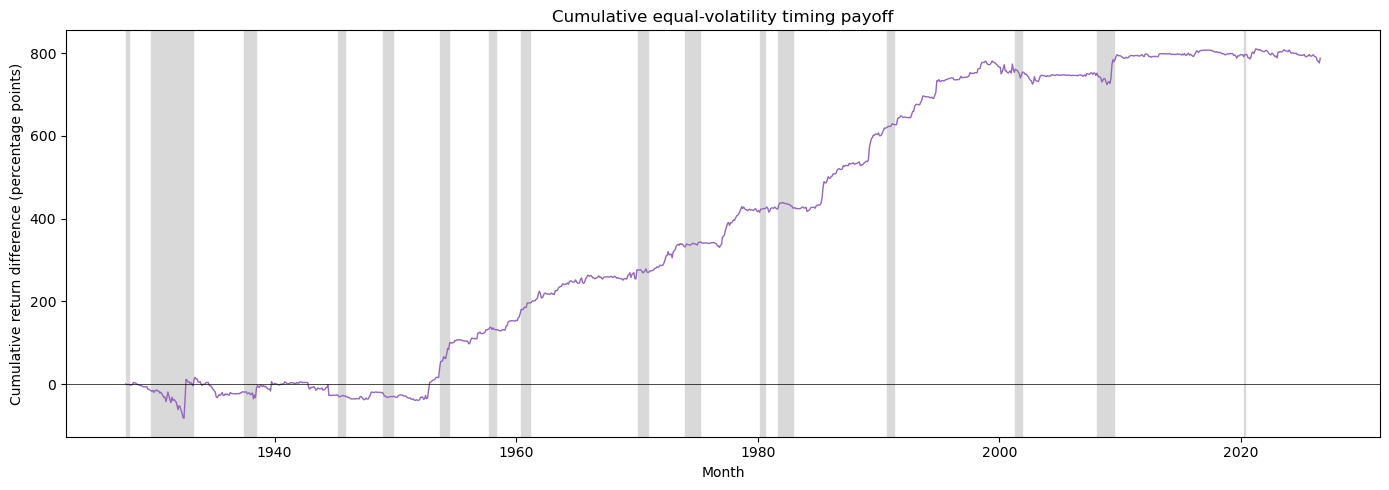

In [10]:
# 5.2 Trace the additive timing payoff through history
plot_momentum_timing_payoff(timing_payoff);

## 6. Expansion and recession performance

This table reports native performance conditional on the retrospective NBER state. It shows how the two return series differ during recessions without treating recession dates as information available to the strategy. Because every weight is positive, volatility timing cannot change the sign of a given month's momentum return; the negative-month frequency is therefore identical. It changes return magnitudes by taking less exposure after volatile months. Average weights are omitted; the next section measures the relationship between the two strategies directly.

In [11]:
# 6. Compare performance across business-cycle states
recession_performance = recession_performance_table(analysis)
recession_performance_labels = {
    'state': 'State', 'strategy': 'Strategy', 'observations': 'N',
    'mean_monthly_pct': 'Mean monthly return (%)',
    'median_monthly_pct': 'Median monthly return (%)',
    'std_monthly_pct': 'Monthly std (%)',
    'annualized_sharpe': 'Annualized SR',
    'negative_months_pct': 'Negative months (%)',
}
display(
    recession_performance.rename(columns=recession_performance_labels)
    .round(3).style.hide(axis='index')
)

State,Strategy,N,Mean monthly return (%),Median monthly return (%),Monthly std (%),Annualized SR,Negative months (%)
Expansion,Momentum,996,0.697000,0.790000,3.719000,0.649000,36.747000
Expansion,Lagged-RV volatility-timed momentum,996,1.291000,0.577000,4.621000,0.968000,36.747000
Recession,Momentum,192,0.157000,1.190000,8.077000,0.067000,40.104000
Recession,Lagged-RV volatility-timed momentum,192,0.921000,0.243000,4.178000,0.764000,40.104000


## 7. Comovement with original momentum

Correlation measures standardized comovement. The **Mom loading** is the slope from the descriptive regression `VT-Mom = intercept + loading × Mom + residual`; it measures how much VT-Mom typically moves when Mom moves by one percentage point. It is not a CAPM beta because the market is not the regressor. It is closely related to an own-factor spanning regression, but correlation or loading alone cannot determine whether the intercept is zero.

The state table shows substantially weaker comovement during recessions. The trailing 120-month figure then shows when that relationship changes through calendar time. Each plotted value uses the current and preceding 119 months; it is a backward-looking diagnostic rather than a trading signal.

State,N,Return correlation,Loading on Mom,R-squared
Full sample,1188,0.452000,0.438000,0.205000
Expansion,996,0.532000,0.661000,0.283000
Recession,192,0.369000,0.191000,0.136000


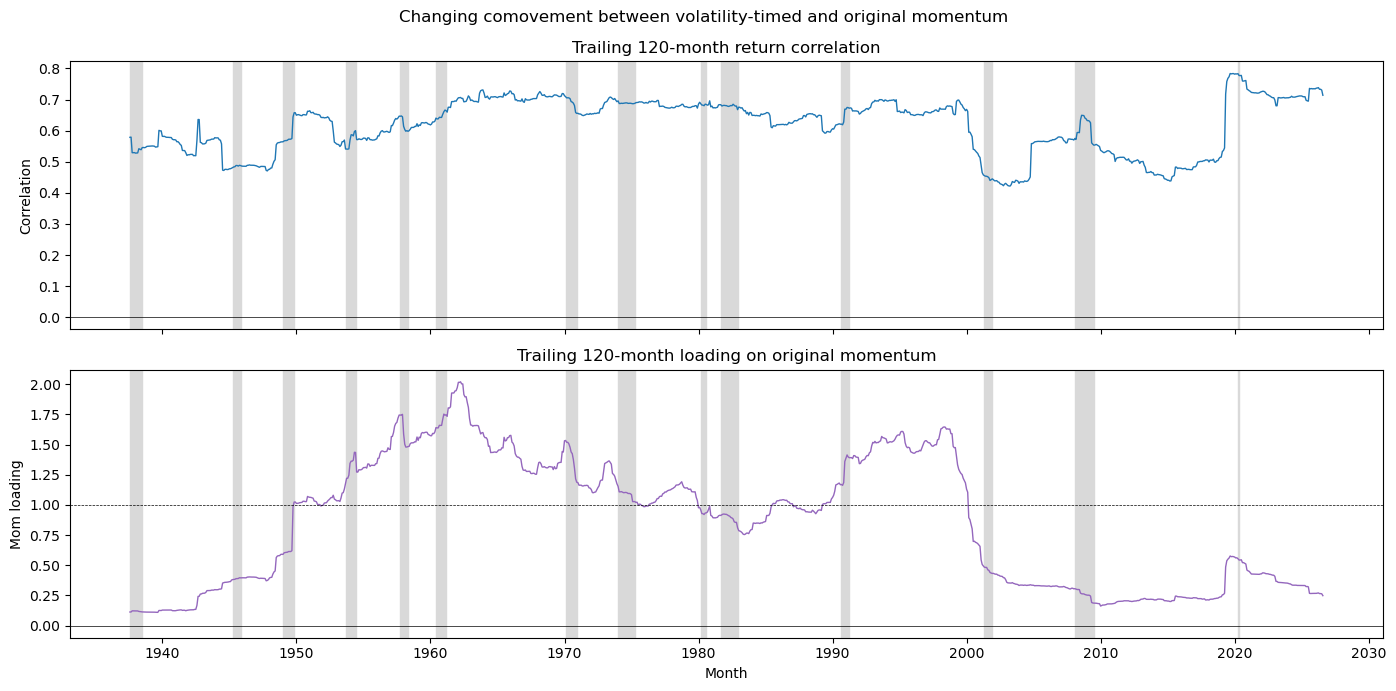

In [12]:
# 7. Compare state-conditional and trailing comovement
comovement = strategy_comovement_table(analysis)
comovement_labels = {
    'state': 'State', 'observations': 'N',
    'correlation': 'Return correlation',
    'mom_loading': 'Loading on Mom', 'r_squared': 'R-squared',
}
display(comovement.rename(columns=comovement_labels).round(3).style.hide(axis='index'))
rolling_relationships = rolling_strategy_relationships(analysis, window=120)
plot_momentum_rolling_relationships(rolling_relationships);

### 7.1 Full-period and recession-interaction loadings

For each regressor—market excess return and Mom—the first specification is the full-period regression $VTMom_t = \alpha + \beta X_t + \varepsilon_t$. The second is $VTMom_t = \alpha_0 + \alpha_1 Recession_t + \beta_0 X_t + \beta_1(Recession_t \times X_t) + \varepsilon_t$. The recession dummy permits an intercept shift; $\beta_0$ is the expansion loading, $\beta_1$ is the recession change, and $\beta_0+\beta_1$ is the total recession loading. With $X_t$ equal to the market this is a conditional market-beta diagnostic; with $X_t$ equal to Mom it is the momentum analogue of Moreira and Muir's Table III.

A negative interaction means VT-Mom has less contemporaneous exposure to the regressor during recessions. It does not mean the strategy predicts recessions: only lagged realized variance determines the weight. Newey–West(12) t-statistics are reported.

In [13]:
# 7.1 Estimate full-period and recession-interaction loadings
recession_loadings = recession_loading_table(analysis, HAC_LAGS)
recession_loading_labels = {
    'relationship': 'Regressor', 'model': 'Specification',
    'estimate': 'Component', 'coefficient': 'Coefficient', 'unit': 'Unit',
    'nw12_t': 'Newey-West(12) t-statistic',
    'observations': 'N', 'r_squared': 'R-squared',
}
display(
    recession_loadings.rename(columns=recession_loading_labels)
    .round(3).style.hide(axis='index')
)

Regressor,Specification,Component,Coefficient,Unit,Newey-West(12) t-statistic,N,R-squared
Market,Unconditional full-period regression,Full-period market beta,-0.013000,Loading,-0.523000,1188,0.000000
Market,Recession interaction regression,Recession dummy (intercept shift),-0.392000,Monthly return (%),-0.885000,1188,0.005000
Market,Recession interaction regression,Market beta in expansions,0.028000,Loading,0.773000,1188,0.005000
Market,Recession interaction regression,Change in market beta during recessions,-0.109000,Loading,-2.316000,1188,0.005000
Market,Recession interaction regression,Total market beta in recessions,-0.081000,Loading,-2.842000,1188,0.005000
Mom,Unconditional full-period regression,Full-period Mom loading,0.438000,Loading,4.740000,1188,0.205000
Mom,Recession interaction regression,Recession dummy (intercept shift),0.061000,Monthly return (%),0.152000,1188,0.264000
Mom,Recession interaction regression,Mom loading in expansions,0.661000,Loading,7.512000,1188,0.264000
Mom,Recession interaction regression,Change in Mom loading during recessions,-0.470000,Loading,-4.470000,1188,0.264000
Mom,Recession interaction regression,Total Mom loading in recessions,0.191000,Loading,2.872000,1188,0.264000


## 8. Main conclusions

Four results stand out:

- **The return distribution changes materially.** Native volatility-timed momentum raises the annualized Sharpe ratio from 0.449 to 0.937, reduces empirical 5% ES from an 11.835% to a 7.826% monthly loss, and improves maximum drawdown from -78.437% to -32.282%. Skewness changes from -3.021 to 1.227.
- **The average payoff comes mainly from scaling up calm periods.** After equalizing full-sample volatility, the timing payoff averages 0.663% per month with a Newey–West(12) t-statistic of 4.026, conditional on the ex-post scale. The lowest lagged-volatility quintile contributes 0.603 percentage points of that mean and has an average weight of 4.233. Quintile 1 has the highest absolute Sharpe ratio; quintile 5 has the largest improvement relative to raw Mom but remains a low-Sharpe state.
- **VT-Mom becomes less like Mom in recessions.** Return correlation declines from 0.532 in expansions to 0.369 in recessions. In the Mom interaction regression, the loading falls from 0.661 to 0.191; the -0.470 change has a Newey–West(12) t-statistic of -4.470. The parallel market regression distinguishes this changing Mom exposure from conventional market beta. Persistent volatility around the Great Depression and GFC helps the lagged rule reduce exposure, but it does not predict recession onsets.
- **The effect is historically uneven and not yet implementable.** The additive equal-volatility payoff is negative early in the sample, rises strongly from roughly the 1950s through the late 1990s, and is much flatter thereafter. The stored normalization is ex post, weights are uncapped (maximum 20.498), annualized scalar-weight turnover is 10.477, and transaction costs are absent. Moreira and Muir's caps of 1.0 and 1.5 are natural separate robustness specifications, but no cap is imposed here because that would change the baseline strategy.